In [2]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels imbalanced-learn xgboost plotly openpyxl

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import statsmodels.api as sm
import imblearn
import xgboost as xgb
import plotly.express as px
import openpyxl

print("Todas as bibliotecas foram carregadas!")

Todas as bibliotecas foram carregadas!


In [4]:
df = pd.read_csv(
    'datatran2026.csv',
    sep=';',
    encoding='latin1',
    low_memory=False,
    dtype={'id': str}
)

In [5]:
df.head(4)

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,mortos,feridos_leves,feridos_graves,ilesos,ignorados,feridos,veiculos,regional,delegacia,uop
0,742921,01/01/2026,quinta-feira,04:04:00,TO,153,155.0,ARAGUAINA,Objeto estático sobre o leito carroçável,Tombamento,...,1,0,0,1,3,0,5,SPRF-TO,DEL02-TO,UOP01-DEL02-TO
1,742942,01/01/2026,quinta-feira,06:40:00,MG,262,146.1,RIO CASCA,Condutor Dormindo,Colisão frontal,...,0,0,4,1,1,4,3,SPRF-MG,DEL03-MG,UOP03-DEL03-MG
2,742943,01/01/2026,quinta-feira,06:58:00,SC,101,193.0,BIGUACU,Reação tardia ou ineficiente do condutor,Colisão lateral mesmo sentido,...,0,1,0,1,2,1,4,SPRF-SC,DEL01-SC,UOP01-DEL01-SC
3,742947,01/01/2026,quinta-feira,07:05:00,DF,60,23.0,BRASILIA,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,1,0,1,1,1,3,SPRF-DF,DEL03-DF,UOP01-DEL03-DF


In [6]:
#transformando id em string
df["id"] = df["id"].astype(str)

In [7]:
#transformando id em string
df["br"] = df["br"].astype(str)

In [8]:
#verificando nulos
df.isnull().sum()

id                         0
data_inversa               0
dia_semana                 0
horario                    0
uf                         0
br                         0
km                         0
municipio                  0
causa_acidente             0
tipo_acidente              0
classificacao_acidente     1
fase_dia                   0
sentido_via                0
condicao_metereologica     0
tipo_pista                 0
tracado_via                0
uso_solo                   0
pessoas                    0
mortos                     0
feridos_leves              0
feridos_graves             0
ilesos                     0
ignorados                  0
feridos                    0
veiculos                   0
regional                   1
delegacia                 12
uop                       26
dtype: int64

In [9]:
#verificando duplicados
df["id"].duplicated().sum()

np.int64(0)

In [10]:
#transformando nulos em  nao informados
df[["classificacao_acidente", "regional", "delegacia", "uop"]] = df[["classificacao_acidente", "regional", "delegacia", "uop"]].fillna("não informado")

In [11]:
df.isnull().sum()

id                        0
data_inversa              0
dia_semana                0
horario                   0
uf                        0
br                        0
km                        0
municipio                 0
causa_acidente            0
tipo_acidente             0
classificacao_acidente    0
fase_dia                  0
sentido_via               0
condicao_metereologica    0
tipo_pista                0
tracado_via               0
uso_solo                  0
pessoas                   0
mortos                    0
feridos_leves             0
feridos_graves            0
ilesos                    0
ignorados                 0
feridos                   0
veiculos                  0
regional                  0
delegacia                 0
uop                       0
dtype: int64

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48712 entries, 0 to 48711
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      48712 non-null  str    
 1   data_inversa            48712 non-null  str    
 2   dia_semana              48712 non-null  str    
 3   horario                 48712 non-null  str    
 4   uf                      48712 non-null  str    
 5   br                      48712 non-null  str    
 6   km                      48712 non-null  float64
 7   municipio               48712 non-null  str    
 8   causa_acidente          48712 non-null  str    
 9   tipo_acidente           48712 non-null  str    
 10  classificacao_acidente  48712 non-null  str    
 11  fase_dia                48712 non-null  str    
 12  sentido_via             48712 non-null  str    
 13  condicao_metereologica  48712 non-null  str    
 14  tipo_pista              48712 non-null  str    
 

In [13]:
#verificando se tem valores negativos
numericos = ["pessoas", "mortos", "feridos_leves", "feridos_graves",  
             "ilesos",  "ignorados", "feridos", "veiculos"]
for coluna in numericos:
    negativos = (df[coluna] < 0).sum()
    print(f"{coluna}: {negativos} valores negativos")

pessoas: 0 valores negativos
mortos: 0 valores negativos
feridos_leves: 0 valores negativos
feridos_graves: 0 valores negativos
ilesos: 0 valores negativos
ignorados: 0 valores negativos
feridos: 0 valores negativos
veiculos: 0 valores negativos


In [14]:
#idenitificando outliers
numericos = ["pessoas", "mortos", "feridos_leves", "feridos_graves",  
             "ilesos",  "ignorados", "feridos", "veiculos"]
for coluna in numericos:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outlier = df[
    (df[coluna] < limite_inferior) |
    (df[coluna] > limite_superior)
    ]
    print(f"{coluna}: {len(outlier)} outliers")

pessoas: 4469 outliers
mortos: 3491 outliers
feridos_leves: 1978 outliers
feridos_graves: 10918 outliers
ilesos: 4401 outliers
ignorados: 1358 outliers
feridos: 20675 outliers
veiculos: 3581 outliers


In [15]:
#comando para verificar a partir de qual numero pra baixo os 75% dos registros tem(3 pra baixo) 
df['pessoas'].quantile(0.75)

np.float64(3.0)

In [16]:
#verificar todas as colunas
pd.set_option('display.max_columns', None)
df.head(5)

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,classificacao_acidente,fase_dia,sentido_via,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas,mortos,feridos_leves,feridos_graves,ilesos,ignorados,feridos,veiculos,regional,delegacia,uop
0,742921,01/01/2026,quinta-feira,04:04:00,TO,153,155.0,ARAGUAINA,Objeto estático sobre o leito carroçável,Tombamento,não informado,Amanhecer,Crescente,Céu Claro,Simples,Aclive;Reta,Não,3,1,0,0,1,3,0,5,SPRF-TO,DEL02-TO,UOP01-DEL02-TO
1,742942,01/01/2026,quinta-feira,06:40:00,MG,262,146.1,RIO CASCA,Condutor Dormindo,Colisão frontal,Com Vítimas Feridas,Pleno dia,Crescente,Céu Claro,Simples,Reta,Não,6,0,0,4,1,1,4,3,SPRF-MG,DEL03-MG,UOP03-DEL03-MG
2,742943,01/01/2026,quinta-feira,06:58:00,SC,101,193.0,BIGUACU,Reação tardia ou ineficiente do condutor,Colisão lateral mesmo sentido,Com Vítimas Feridas,Amanhecer,Crescente,Nublado,Dupla,Curva,Sim,3,0,1,0,1,2,1,4,SPRF-SC,DEL01-SC,UOP01-DEL01-SC
3,742947,01/01/2026,quinta-feira,07:05:00,DF,60,23.0,BRASILIA,Reação tardia ou ineficiente do condutor,Colisão traseira,Com Vítimas Feridas,Pleno dia,Decrescente,Céu Claro,Dupla,Aclive;Reta,Não,3,0,1,0,1,1,1,3,SPRF-DF,DEL03-DF,UOP01-DEL03-DF
4,742960,01/01/2026,quinta-feira,06:17:00,MT,163,1044.0,MATUPA,Transitar na contramão,Colisão frontal,Com Vítimas Feridas,Amanhecer,Decrescente,Sol,Simples,Reta,Não,3,0,0,1,1,3,1,5,SPRF-MT,DEL06-MT,UOP03-DEL06-MT


In [17]:
#ver se os valores batem com a soma das colunas
(df["pessoas"] ==(
    df["mortos"] + 
    df["ilesos"] + 
    df["feridos"] + 
    df["ignorados"]
)).sum()

np.int64(46139)

In [18]:
#verificando erros da soma 
df['diferenca_pessoas'] = (
    df['pessoas'] -
    (df['mortos'] + df['ilesos'] + df['feridos'] + df['ignorados'])
)

In [19]:
df['diferenca_pessoas'].value_counts()

diferenca_pessoas
 0     46139
-1      1532
-2       734
-3       146
-4        74
-5        42
-6        10
-7        10
-8         8
-11        4
-10        4
-12        3
-9         3
-13        2
-14        1
Name: count, dtype: int64

In [20]:
(df["feridos"] == df["feridos_leves"] + df["feridos_graves"]).sum()

np.int64(48712)

In [21]:
#atribuir que a coluna pessoas tem que ser a soma dessas colunas
df["pessoas"] = (
    df["mortos"] +
    df["feridos"] +
    df["ilesos"] +
    df["ignorados"]
)

In [22]:
#ver se deu certo 
(df["pessoas"] == (
    df["mortos"] +
    df["feridos"] +
    df["ilesos"] +
    df["ignorados"]
)).sum()

np.int64(48712)

In [23]:
df['data_inversa'] = pd.to_datetime(
    df['data_inversa'],
    format='%d/%m/%Y',
    errors='coerce'
)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48712 entries, 0 to 48711
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      48712 non-null  str           
 1   data_inversa            48712 non-null  datetime64[us]
 2   dia_semana              48712 non-null  str           
 3   horario                 48712 non-null  str           
 4   uf                      48712 non-null  str           
 5   br                      48712 non-null  str           
 6   km                      48712 non-null  float64       
 7   municipio               48712 non-null  str           
 8   causa_acidente          48712 non-null  str           
 9   tipo_acidente           48712 non-null  str           
 10  classificacao_acidente  48712 non-null  str           
 11  fase_dia                48712 non-null  str           
 12  sentido_via             48712 non-null  str           
 1

In [24]:
df["ano"] = df["data_inversa"].dt.year
df["mes"] = df["data_inversa"].dt.month
df["dia"] = df["data_inversa"].dt.day
df['dia_semana_num'] = df['data_inversa'].dt.dayofweek

df.head()

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,classificacao_acidente,fase_dia,sentido_via,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas,mortos,feridos_leves,feridos_graves,ilesos,ignorados,feridos,veiculos,regional,delegacia,uop,diferenca_pessoas,ano,mes,dia,dia_semana_num
0,742921,2026-01-01,quinta-feira,04:04:00,TO,153,155.0,ARAGUAINA,Objeto estático sobre o leito carroçável,Tombamento,não informado,Amanhecer,Crescente,Céu Claro,Simples,Aclive;Reta,Não,5,1,0,0,1,3,0,5,SPRF-TO,DEL02-TO,UOP01-DEL02-TO,-2,2026,1,1,3
1,742942,2026-01-01,quinta-feira,06:40:00,MG,262,146.1,RIO CASCA,Condutor Dormindo,Colisão frontal,Com Vítimas Feridas,Pleno dia,Crescente,Céu Claro,Simples,Reta,Não,6,0,0,4,1,1,4,3,SPRF-MG,DEL03-MG,UOP03-DEL03-MG,0,2026,1,1,3
2,742943,2026-01-01,quinta-feira,06:58:00,SC,101,193.0,BIGUACU,Reação tardia ou ineficiente do condutor,Colisão lateral mesmo sentido,Com Vítimas Feridas,Amanhecer,Crescente,Nublado,Dupla,Curva,Sim,4,0,1,0,1,2,1,4,SPRF-SC,DEL01-SC,UOP01-DEL01-SC,-1,2026,1,1,3
3,742947,2026-01-01,quinta-feira,07:05:00,DF,60,23.0,BRASILIA,Reação tardia ou ineficiente do condutor,Colisão traseira,Com Vítimas Feridas,Pleno dia,Decrescente,Céu Claro,Dupla,Aclive;Reta,Não,3,0,1,0,1,1,1,3,SPRF-DF,DEL03-DF,UOP01-DEL03-DF,0,2026,1,1,3
4,742960,2026-01-01,quinta-feira,06:17:00,MT,163,1044.0,MATUPA,Transitar na contramão,Colisão frontal,Com Vítimas Feridas,Amanhecer,Decrescente,Sol,Simples,Reta,Não,5,0,0,1,1,3,1,5,SPRF-MT,DEL06-MT,UOP03-DEL06-MT,-2,2026,1,1,3


In [25]:
#acidentes por dia 
acidente_dia = (
    df.groupby("data_inversa").size()
    .reset_index(name="total_acidente")
)
acidente_dia.head(5)

,data_inversa,total_acidente
0,2026-01-01,195
1,2026-01-02,185
2,2026-01-03,203
3,2026-01-04,210
4,2026-01-05,186


In [26]:
print('Data inicial:', acidente_dia['data_inversa'].min())
print('Data final:', acidente_dia['data_inversa'].max())
print('Quantidade de dias com registros:', len(acidente_dia))

Data inicial: 2026-01-01 00:00:00
Data final: 2026-08-31 00:00:00
Quantidade de dias com registros: 243


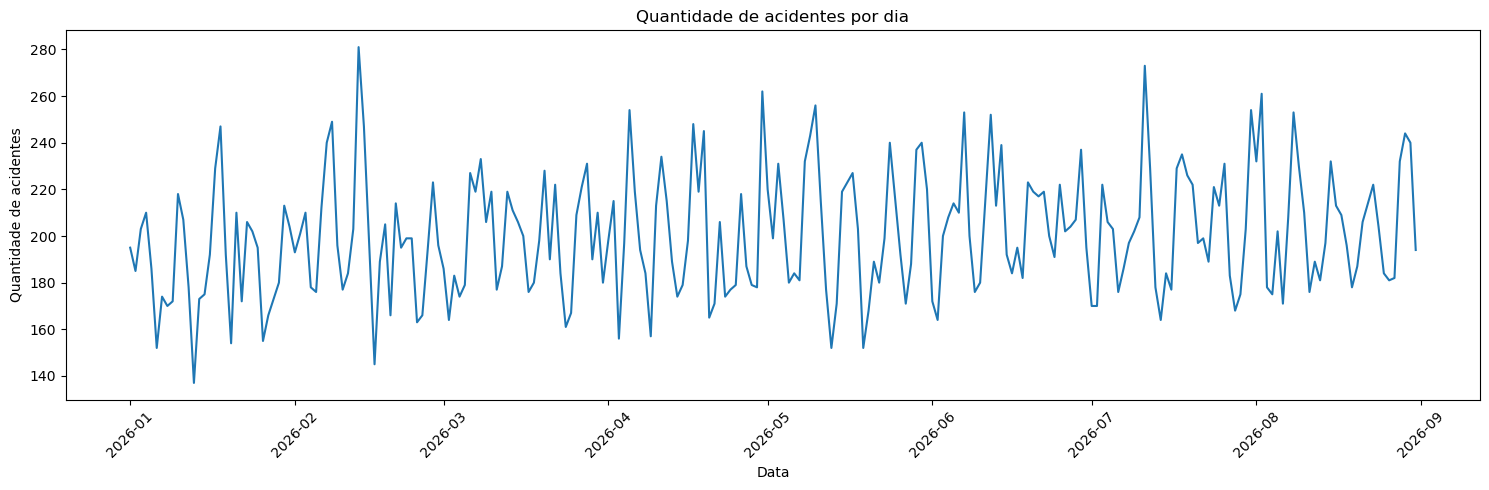

In [27]:
plt.figure(figsize=(15, 5))

plt.plot(
    acidente_dia['data_inversa'],
    acidente_dia['total_acidente']
)

plt.title('Quantidade de acidentes por dia')
plt.xlabel('Data')
plt.ylabel('Quantidade de acidentes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
display(acidente_dia['data_inversa'])

0     2026-01-01
1     2026-01-02
2     2026-01-03
3     2026-01-04
4     2026-01-05
         ...    
238   2026-08-27
239   2026-08-28
240   2026-08-29
241   2026-08-30
242   2026-08-31
Name: data_inversa, Length: 243, dtype: datetime64[us]

In [29]:
acidente_dia['dia_semana_num'] = (
    acidente_dia['data_inversa'].dt.dayofweek
)
acidente_dia.head()

,data_inversa,total_acidente,dia_semana_num
0,2026-01-01,195,3
1,2026-01-02,185,4
2,2026-01-03,203,5
3,2026-01-04,210,6
4,2026-01-05,186,0


In [30]:
media_dia_semana = (
    acidente_dia.groupby('dia_semana_num')['total_acidente']
    .mean()
    .reindex(range(7))
    .reset_index()
)


In [31]:
dias = {
    0: 'Segunda',
    1: 'Terça',
    2: 'Quarta',
    3: 'Quinta',
    4: 'Sexta',
    5: 'Sábado',
    6: 'Domingo'
}
media_dia_semana["dia_semana"] = (
    media_dia_semana["dia_semana_num"].map(dias)
)
display(media_dia_semana)

,dia_semana_num,total_acidente,dia_semana
0,0,194.028571,Segunda
1,1,177.970588,Terça
2,2,183.000000,Quarta
3,3,189.400000,Quinta
4,4,215.514286,Sexta
5,5,219.028571,Sábado
6,6,223.142857,Domingo


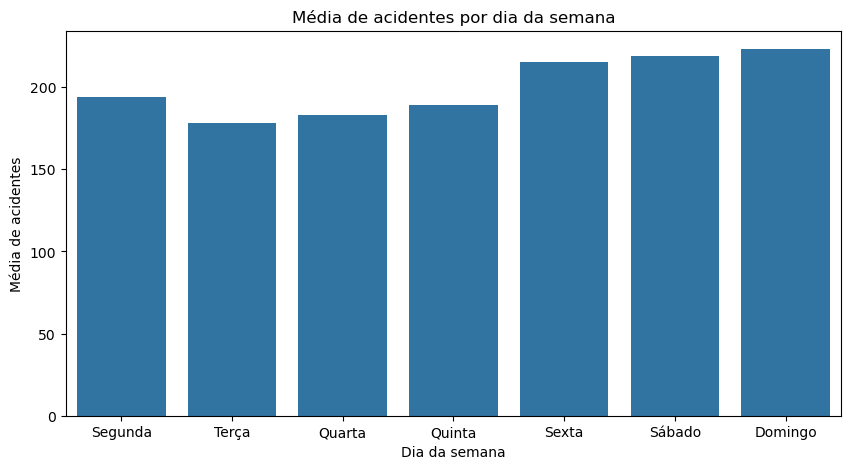

In [32]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=media_dia_semana,
    x='dia_semana',
    y='total_acidente'
)

plt.title('Média de acidentes por dia da semana')
plt.xlabel('Dia da semana')
plt.ylabel('Média de acidentes')
plt.show()

In [33]:
acidente_dia['media_movel_7'] = (
    acidente_dia['total_acidente']
    .rolling(window=31)
    .mean()
)
display(acidente_dia.head(31))

,data_inversa,total_acidente,dia_semana_num,media_movel_7
0,2026-01-01,195,3,NaN
1,2026-01-02,185,4,NaN
2,2026-01-03,203,5,NaN
3,2026-01-04,210,6,NaN
4,2026-01-05,186,0,NaN
5,2026-01-06,152,1,NaN
6,2026-01-07,174,2,NaN
7,2026-01-08,170,3,NaN
8,2026-01-09,172,4,NaN
9,2026-01-10,218,5,NaN


In [34]:
acidente_dia['mes'] = acidente_dia['data_inversa'].dt.month
media_mensal = acidente_dia.groupby('mes')['total_acidente'].mean().round().astype("Int64")
media_mensal

mes
1    188
2    200
3    198
4    199
5    204
6    206
7    203
8    206
Name: total_acidente, dtype: Int64

In [35]:
from sklearn.linear_model import LinearRegression
import numpy as np
X = np.array(media_mensal.index).reshape(-1, 1)
y = media_mensal.values

In [70]:
modelo = LinearRegression()

modelo.fit(X, y)
proximos_meses = np.array([9, 10, 11, 12]).reshape(-1, 1)

previsoes = modelo.predict(proximos_meses).round().astype(int)
previsoes

array([210, 212, 214, 216])

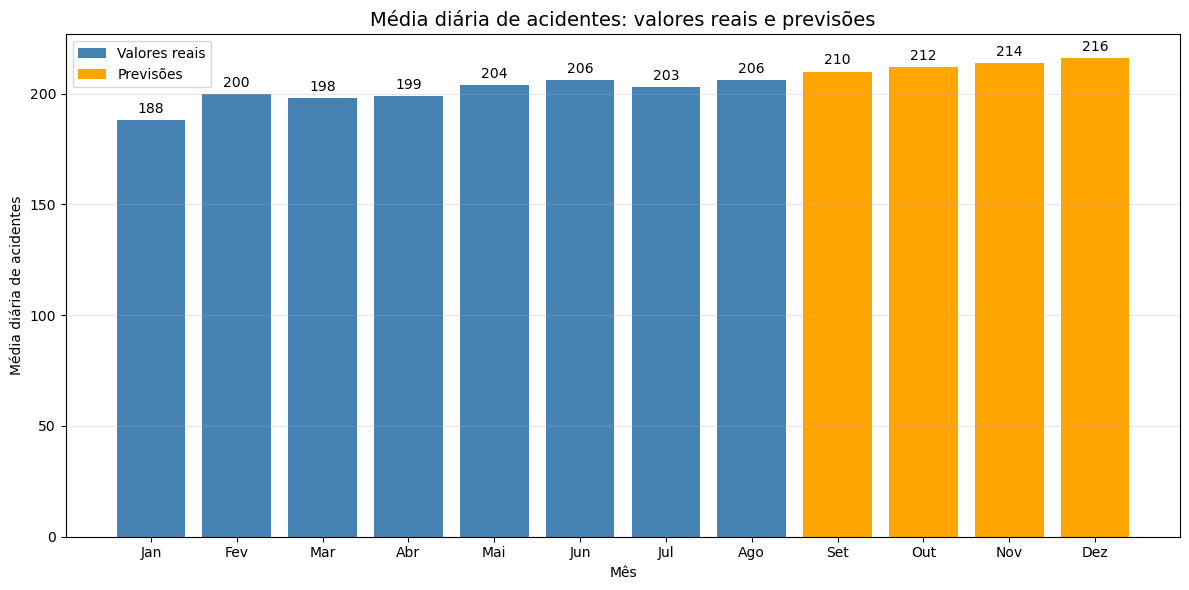

In [75]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Meses previstos
meses = np.array([9, 10, 11, 12])

# Juntar valores reais e previstos
dados_grafico = pd.concat([
    media_mensal,
    pd.Series(previsoes, index=meses)
])

# Criar gráfico
plt.figure(figsize=(12, 6))

# Azul para valores reais e laranja para previsões
cores = ['steelblue'] * len(media_mensal) + ['orange'] * len(previsoes)

barras = plt.bar(
    dados_grafico.index,
    dados_grafico.values,
    color=cores
)

# Adicionar valores acima das barras
plt.bar_label(barras, fmt='%.0f', padding=3)

# Títulos e legendas
plt.title('Média diária de acidentes: valores reais e previsões', fontsize=14)
plt.xlabel('Mês')
plt.ylabel('Média diária de acidentes')

plt.xticks(
    range(1, 13),
    ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
     'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
)

# Legenda
from matplotlib.patches import Patch

legenda = [
    Patch(facecolor='steelblue', label='Valores reais'),
    Patch(facecolor='orange', label='Previsões')
]

plt.legend(handles=legenda)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
dados_grafico.to_excel('media_acidentes_previsoes.xlsx', index=True)

In [39]:
display(media_dia_semana)

,dia_semana_num,total_acidente,dia_semana
0,0,194.028571,Segunda
1,1,177.970588,Terça
2,2,183.000000,Quarta
3,3,189.400000,Quinta
4,4,215.514286,Sexta
5,5,219.028571,Sábado
6,6,223.142857,Domingo


In [40]:
print(df.shape)

print(df.head())

print(df.empty)

(48712, 33)
       id data_inversa    dia_semana   horario  uf   br      km  municipio  \
0  742921   2026-01-01  quinta-feira  04:04:00  TO  153   155.0  ARAGUAINA   
1  742942   2026-01-01  quinta-feira  06:40:00  MG  262   146.1  RIO CASCA   
2  742943   2026-01-01  quinta-feira  06:58:00  SC  101   193.0    BIGUACU   
3  742947   2026-01-01  quinta-feira  07:05:00  DF   60    23.0   BRASILIA   
4  742960   2026-01-01  quinta-feira  06:17:00  MT  163  1044.0     MATUPA   

                             causa_acidente                  tipo_acidente  \
0  Objeto estático sobre o leito carroçável                     Tombamento   
1                         Condutor Dormindo                Colisão frontal   
2  Reação tardia ou ineficiente do condutor  Colisão lateral mesmo sentido   
3  Reação tardia ou ineficiente do condutor               Colisão traseira   
4                    Transitar na contramão                Colisão frontal   

  classificacao_acidente   fase_dia  sentido_via c

In [41]:
df.to_excel('acidentes_tratados.xlsx', index=False)

print("Arquivo exportado!")

Arquivo exportado!


In [42]:
# Agrupando acidentes por estado e mês

base_mensal_estado = (
    df.dropna(subset=['data_inversa', 'uf', 'id'])
    .assign(mes_ref=lambda x: x['data_inversa'].dt.to_period('M').dt.to_timestamp())
    .groupby(['uf', 'mes_ref'])
    .agg(total_acidentes=('id', 'nunique'))
    .reset_index()
)

base_mensal_estado.head(10)

,uf,mes_ref,total_acidentes
0,AC,2026-01-01,20
1,AC,2026-02-01,20
2,AC,2026-03-01,35
3,AC,2026-04-01,19
4,AC,2026-05-01,25
5,AC,2026-06-01,30
6,AC,2026-07-01,31
7,AC,2026-08-01,31
8,AL,2026-01-01,55
9,AL,2026-02-01,47


In [43]:
# Criar sequência completa de meses

meses = pd.date_range(
    start=base_mensal_estado['mes_ref'].min(),
    end=base_mensal_estado['mes_ref'].max(),
    freq='MS'
)

estados = base_mensal_estado['uf'].unique()

grade = pd.MultiIndex.from_product(
    [estados, meses],
    names=['uf', 'mes_ref']
).to_frame(index=False)

base_mensal_estado = grade.merge(
    base_mensal_estado,
    on=['uf', 'mes_ref'],
    how='left'
)

base_mensal_estado['total_acidentes'] = (
    base_mensal_estado['total_acidentes'].fillna(0)
)

In [44]:
from sklearn.linear_model import LinearRegression
import numpy as np

previsoes = []

for estado, grupo in base_mensal_estado.groupby('uf'):

    grupo = grupo.sort_values('mes_ref')

    X = np.arange(len(grupo)).reshape(-1, 1)
    y = grupo['total_acidentes'].values

    modelo = LinearRegression()
    modelo.fit(X, y)

    # Prever os próximos 3 meses
    X_futuro = np.arange(
        len(grupo), len(grupo) + 4
    ).reshape(-1, 1)

    valores_previstos = modelo.predict(X_futuro)

    datas_futuras = pd.date_range(
        start=grupo['mes_ref'].max() + pd.offsets.MonthBegin(1),
        periods=4,
        freq='MS'
    )

    for data, valor in zip(datas_futuras, valores_previstos):

        previsoes.append({
            'uf': estado,
            'mes_ref': data,
            'total_acidentes_previstos': max(0, round(valor))
        })

previsoes_estado = pd.DataFrame(previsoes)

previsoes_estado.head(16)

,uf,mes_ref,total_acidentes_previstos
0,AC,2026-09-01,33
1,AC,2026-10-01,34
2,AC,2026-11-01,36
3,AC,2026-12-01,37
4,AL,2026-09-01,54
5,AL,2026-10-01,54
6,AL,2026-11-01,55
7,AL,2026-12-01,55
8,AM,2026-09-01,23
9,AM,2026-10-01,24


In [45]:
# Preparar dados reais
historico_estado = base_mensal_estado.rename(
    columns={'total_acidentes': 'total_acidentes_previstos'}
)

historico_estado['tipo'] = 'Real'

# Identificar previsões
previsoes_estado['tipo'] = 'Previsão'

# Juntar tudo
resultado_estado = pd.concat(
    [historico_estado, previsoes_estado],
    ignore_index=True
)

resultado_estado = resultado_estado.sort_values(
    ['uf', 'mes_ref']
)

resultado_estado.head(20)

,uf,mes_ref,total_acidentes_previstos,tipo
0,AC,2026-01-01,20,Real
1,AC,2026-02-01,20,Real
2,AC,2026-03-01,35,Real
3,AC,2026-04-01,19,Real
4,AC,2026-05-01,25,Real
5,AC,2026-06-01,30,Real
6,AC,2026-07-01,31,Real
7,AC,2026-08-01,31,Real
216,AC,2026-09-01,33,Previsão
217,AC,2026-10-01,34,Previsão


In [46]:
resultado_estado.to_excel(
    'previsao_acidentes_por_estado.xlsx',
    index=False
)